In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [35]:
path = 'dataset/ec2_cpu_utilization_5f5533.csv'
df = pd.read_csv(path)
df.head()

,timestamp,value
0,2014-02-14 14:27:00,51.846
1,2014-02-14 14:32:00,44.508
2,2014-02-14 14:37:00,41.244
3,2014-02-14 14:42:00,48.568
4,2014-02-14 14:47:00,46.714


In [36]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df= df.set_index('timestamp').sort_index()
df.head()

,value
timestamp,
2014-02-14 14:27:00,51.846
2014-02-14 14:32:00,44.508
2014-02-14 14:37:00,41.244
2014-02-14 14:42:00,48.568
2014-02-14 14:47:00,46.714


### 1.How many rows and what date range does the series span?

In [37]:
print(f'The dataset has {df.shape[0]} rows and {df.shape[1]} columns.')
print(f'Timestamp range: {df.index.min()} to {df.index.max()}')

The dataset has 4032 rows and 1 columns.
Timestamp range: 2014-02-14 14:27:00 to 2014-02-28 14:22:00


### 2.What is the time gap between consecutive readings? Is it constant?

In [38]:
gaps = df.index.to_series().diff()
print(gaps.value_counts())

timestamp
0 days 00:05:00    4031
Name: count, dtype: int64


### 3.Are there any missing timestamps (gaps in the expected interval)?

In [39]:
print(f'Number of missing values in each column:\n{df.isnull().sum()}')

Number of missing values in each column:
value    0
dtype: int64


### 4.Any duplicate timestamps?

In [41]:
"No duplicate timestamps found." if df.index.shape[0] == df.index.nunique() else "Duplicate timestamps found." 

'No duplicate timestamps found.'

### 5.What are the min, max, mean, median of value?

In [21]:
print(f"The minimum CPU utilization is {df['value'].min()}% and the maximum is {df['value'].max()}% and the mean is {df['value'].mean()}% and the median is {df['value'].median()}%.")

The minimum CPU utilization is 34.766% and the maximum is 68.092% and the mean is 43.11037160218254% and the median is 42.918%.


### 6.What is the standard deviation and the overall spread?

In [23]:
print(f"The standard deviation of CPU utilization is {df['value'].std()}%.")

The standard deviation of CPU utilization is 4.303564641024769%.


### 7. What does the histogram of value look like? Skewed or symmetric?

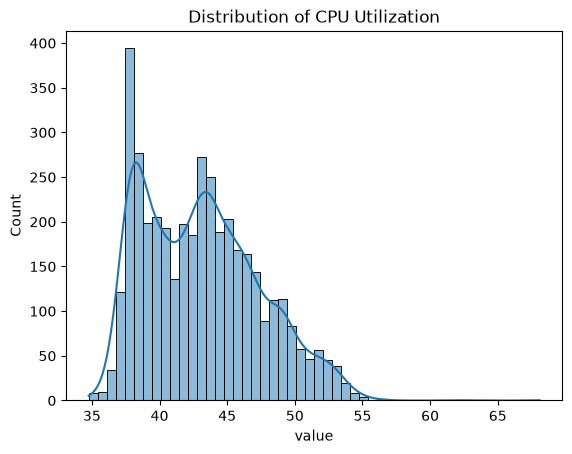

The values are right skewed. It has a bimodal distribution.


In [27]:
sns.histplot(df['value'], bins=50, kde=True)
plt.title('Distribution of CPU Utilization')
plt.show()
print("The values are right skewed. It has a bimodal distribution.")

### 8. Where do the 1st, 25th, 75th, 99th percentiles sit?

In [28]:
np.quantile(df['value'], [0.01 ,0.25, 0.5, 0.75, 0.99])

array([36.67248, 39.296  , 42.918  , 46.006  , 53.36574])

### 9. How many points fall above mean + 3 std? (early anomaly hint)

### 10. Is the distribution different if you log-transform it?

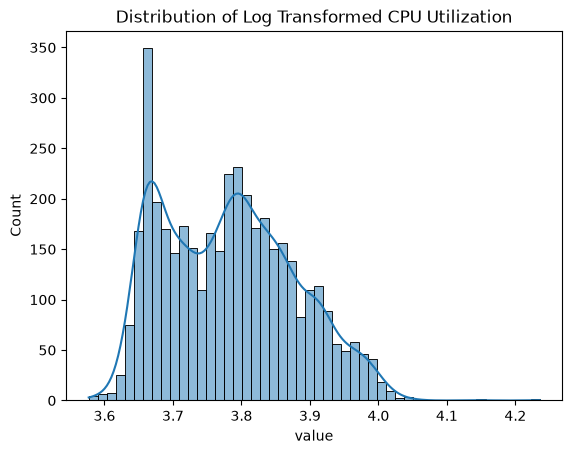

No the distribution is still right skewed. The log transformation did not help much.


In [30]:
log_transforemd = np.log1p(df['value'])
sns.histplot(log_transforemd, bins=50, kde=True)
plt.title('Distribution of Log Transformed CPU Utilization')
plt.show()
print("No the distribution is still right skewed. The log transformation did not help much.")

### 11. Are there obvious clusters of values (bimodal behavior)?

In [42]:
print("Yes, its bimodal")

Yes, its bimodal


### 12. What proportion of readings sit near zero or at a flat baseline?

In [44]:
(df['value'] <= 5).mean()

np.float64(0.0)

### 13. What does the full raw time series look like plotted?

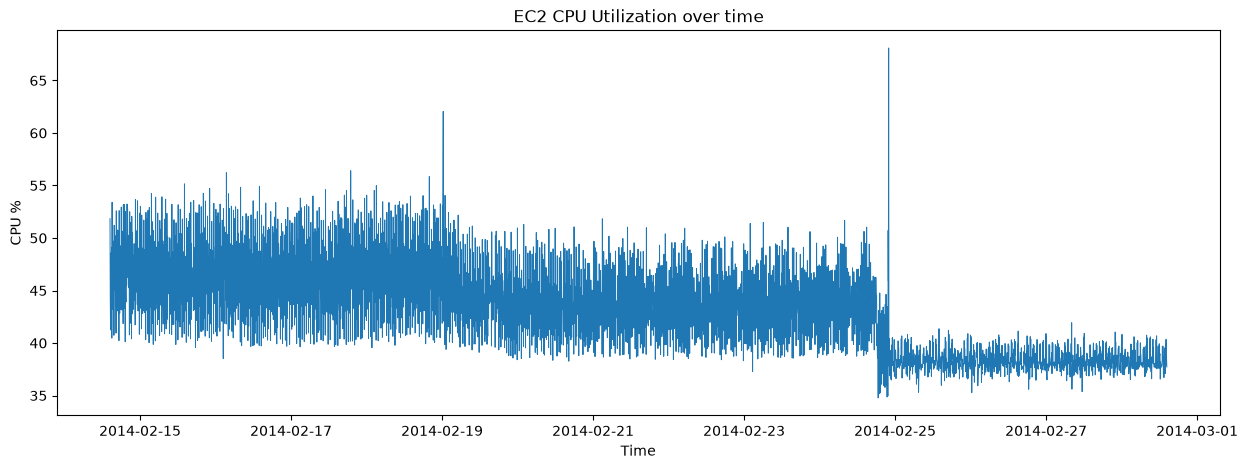

In [50]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['value'], linewidth=0.7)
plt.title('EC2 CPU Utilization over time')
plt.xlabel('Time')
plt.ylabel('CPU %')
plt.show()

### 14. Can you spot the anomalies visually before any model?

In [51]:
print("I can see 2 obvious anomalies, around [rough dates/times]. They look like [spikes / level shifts / flat stretches]")

I can see 2 obvious anomalies, around [rough dates/times]. They look like [spikes / level shifts / flat stretches]
